### 第零步：清除上次的实验结果

In [19]:
import json

with open("performance.json", "w", encoding="utf-8") as f:
	json.dump([], f)

with open("configs.json", "w", encoding="utf-8") as f:
	json.dump([], f)

### 第一步：判断是否连续

In [20]:
import re

def _getIdx(node_name):
	### eg. '/model.0/conv/Conv' -> '0'\
	m = re.search(r'model\.(\d+)', node_name)
	idx = int(m.group(1)) 
	return idx

In [21]:
from collections import Counter
from itertools import groupby

def _checkContinuous(arr):
	### arr: [(node_name, weight_size), ...]
	continuousArr = []

	# 第一步：统计每个idx出现次数。
	count = Counter(_getIdx(node_name) for node_name, _ in arr)

	#第二步：若idx出现次数大于1，且连续出现，则作为数组加入continousArr。
	for idx, group in groupby(arr, key=lambda x: _getIdx(x[0])):
		group = list(group)
		if count[idx] > 1 and len(group) == count[idx]:
			continuousArr.append(group)
		else:
			continuousArr.extend(group)

	# 第三步：返回continuousArr
	return continuousArr

### 简单测试
arr = [('/model.0/conv/Conv', 10), ('/model.2/conv/Conv', 20), ('/model.2/conv/Conv', 30), ('/model.1/conv/Conv', 40)]
print(_checkContinuous(arr))

[('/model.0/conv/Conv', 10), [('/model.2/conv/Conv', 20), ('/model.2/conv/Conv', 30)], ('/model.1/conv/Conv', 40)]


### 第二步：计算百分比
#### getClosestNodes(arr, target) -> closestNodes

arr: [(node_name, weight_size), ...]

In [22]:
def _reshape(obj):
	### [(x1, y1), (x2, y2), ...] -> [ [x1, x2, ...], y1+y2+... ]
	if isinstance(obj, list):
		x, y = [], 0
		for i in obj:
			x.append(i[0])
			y += i[1]
	else:
		x, y = obj[0], obj[1]

	return [x, y]

In [23]:
def getFirstNBlocks(arr, n):
	arr = [tuple(p) for p in arr]       
	continuousArr = _checkContinuous(arr)

	### input validation
	if n > len(continuousArr):
		raise AssertionError('Invalid inpunt n.')
	
	firstNBlocks = [_reshape(i)[0] for i in continuousArr[:n]]

	firstNBlocks = [y for x in firstNBlocks for y in (x if isinstance(x, list) else [x])]
	return firstNBlocks

### 简单测试
# arr = [('/model.0/conv/Conv', 10), ('/model.2/conv/Conv', 20), ('/model.2/conv/Conv', 30), ('/model.1/conv/Conv', 40)]
# target = 1
# print(getFirstNBlocks(arr, target))

In [24]:
def getClosestNodes(arr, target):   
	arr = [tuple(p) for p in arr]       
	continuousArr = _checkContinuous(arr)
	reshapedArr = [_reshape(i) for i in continuousArr]

	closestNodes, closestParam = [], 0

	for k, (nodes, param) in enumerate(reshapedArr):
		if abs(target - closestParam - param) < abs(target - closestParam):
			closestParam += param
			closestNodes.append(nodes)
		else:
			break

	closestNodes = [y for x in closestNodes for y in (x if isinstance(x, list) else [x])]
	return closestNodes

### 简单测试
# arr = [('/model.0/conv/Conv', 10), ('/model.2/conv/Conv', 20), ('/model.2/conv/Conv', 30), ('/model.1/conv/Conv', 40)]
# target = 70
# print(getClosestNodes(arr, target))

### 第三步：组装

getQuantizedNodes(arrs, total_param) -> NODES

arrs: {"arr_name": arr[[],[]]}
NODES: {(closestNodes):(ratio, arr)}

In [25]:
def calTargetParam(targetRatio, totalParam):
	return targetRatio * totalParam
# (1 - targetRatio) / 0.75 * totalParam

In [26]:
def addConfig(targetRatio, targetParam, firstN, actualRatio, actualParam, got, arr_name):
	config = {
		'arr_name': arr_name,
		'targetRatio': targetRatio,
		'targetParam': targetParam,
		'firstN': firstN,
		'actualRatio': actualRatio,
		'actualParam': actualParam,		
		'got': got,
	}
	return config

In [27]:
def addQuantizedNodes(arr, arrName, NODES, totalParam, targetRatio=None, n=None):
	### target and total for Ratio Mode, while n for Index Mode.
	### add and config

	targetParam = None

	### Index Mode
	if n is not None:
		got = getFirstNBlocks(arr, n)

	### Ratio Mode
	elif targetRatio is not None:
		targetParam = calTargetParam(targetRatio, totalParam)
		got = getClosestNodes(arr, targetParam)

	else:
		raise ValueError('Either targetRatio (Ratio Mode) or n (Index Mode) must be given.')

	actualParam = sum(w for _, w in arr if _ in got)
	actualRatio = actualParam / totalParam

	NODES[tuple(got)].append((actualRatio, arrName))

	config = addConfig(
				targetRatio=targetRatio,
				targetParam=targetParam,
				firstN=n,
				actualParam=actualParam,
				actualRatio=actualRatio,
				got=got,
				arr_name=arrName
			)
	return config, actualRatio 

In [28]:
from collections import defaultdict
from itertools import product

def getQuantizedNodes(arrs, total_param, step=None):
	### step for Ratio Mode, n for Index Mode (default: all blocks of the baseline)
	### the first item in arrs is the baseline
	NODES = defaultdict(list)

	configs = []
	baselineRatios = []

	first, *rest = arrs.items()

	if step is not None:
		for targetRatioInt in range(1, step-1):
			name, arr = first 
			targetRatio = targetRatioInt / step

			config, baselineRatio = addQuantizedNodes(arr, name, NODES, total_param, targetRatio=targetRatio)
			
			configs.append(config)
			baselineRatios.append(baselineRatio)

	else:
		name, arr = first
		n = len(_checkContinuous([tuple(p) for p in arr]))

		for i in range(1, n): ### 跳过全量化 n=len
			config, baselineRatio = addQuantizedNodes(arr, name, NODES, total_param, n=i)

			configs.append(config)
			baselineRatios.append(baselineRatio)

	for (name, arr), baselineRatio in product(rest, baselineRatios):
		config, _ = addQuantizedNodes(arr, name, NODES, total_param, targetRatio=baselineRatio)
		configs.append(config)
	
	import json

	with open('configs.json', 'w') as f:
		json.dump({
			'baselineRatios': baselineRatios,
			"NODES":list(NODES.values()),
			'configs': configs,
		}, f, indent=4)
		
	return NODES

### 第四步：获取量化节点

In [29]:
arr_block_layer = [['/model.0/conv/Conv', 432], ['/model.7/conv/Conv', 294912], ['/model.5/conv/Conv', 147456], ['/model.20/conv/Conv', 147456], ['/model.9/cv2/conv/Conv', 131072], ['/model.9/cv1/conv/Conv', 32768], ['/model.17/conv/Conv', 36864], ['/model.3/conv/Conv', 36864], ['/model.22/cv1/conv/Conv', 98304], ['/model.22/cv2/conv/Conv', 98304], ['/model.22/m.0/m.0.0/cv2/conv/Conv', 73728], ['/model.22/m.0/m.0.0/cv1/conv/Conv', 73728], ['/model.22/m.0/m.0.1/attn/qkv/conv/Conv', 32768], ['/model.22/m.0/m.0.1/ffn/ffn.0/conv/Conv', 32768], ['/model.22/m.0/m.0.1/ffn/ffn.1/conv/Conv', 32768], ['/model.8/cv2/conv/Conv', 98304], ['/model.8/cv1/conv/Conv', 65536], ['/model.8/m.0/m/m.0/cv1/conv/Conv', 36864], ['/model.8/m.0/m/m.1/cv2/conv/Conv', 36864], ['/model.8/m.0/m/m.1/cv1/conv/Conv', 36864], ['/model.8/m.0/m/m.0/cv2/conv/Conv', 36864], ['/model.22/m.0/m.0.1/attn/proj/conv/Conv', 16384], ['/model.8/m.0/cv3/conv/Conv', 16384], ['/model.8/m.0/cv2/conv/Conv', 8192], ['/model.8/m.0/cv1/conv/Conv', 8192], ['/model.10/cv1/conv/Conv', 65536], ['/model.10/cv2/conv/Conv', 65536], ['/model.10/m/m.0/ffn/ffn.1/conv/Conv', 32768], ['/model.10/m/m.0/attn/qkv/conv/Conv', 32768], ['/model.10/m/m.0/ffn/ffn.0/conv/Conv', 32768], ['/model.10/m/m.0/attn/proj/conv/Conv', 16384], ['/model.13/cv1/conv/Conv', 49152], ['/model.13/cv2/conv/Conv', 24576], ['/model.13/m.0/m/m.0/cv1/conv/Conv', 9216], ['/model.13/m.0/m/m.1/cv2/conv/Conv', 9216], ['/model.13/m.0/m/m.1/cv1/conv/Conv', 9216], ['/model.13/m.0/m/m.0/cv2/conv/Conv', 9216], ['/model.19/cv1/conv/Conv', 24576], ['/model.19/cv2/conv/Conv', 24576], ['/model.23/one2one_cv4.2/one2one_cv4.2.0/conv/Conv', 73728], ['/model.23/proto/cv2/conv/Conv', 36864], ['/model.23/proto/cv1/conv/Conv', 36864], ['/model.23/proto/feat_fuse/conv/Conv', 36864], ['/model.23/one2one_cv4.1/one2one_cv4.1.0/conv/Conv', 36864], ['/model.23/one2one_cv2.2/one2one_cv2.2.0/conv/Conv', 36864], ['/model.23/one2one_cv3.2/one2one_cv3.2.0/one2one_cv3.2.0.1/conv/Conv', 20480], ['/model.23/one2one_cv2.1/one2one_cv2.1.0/conv/Conv', 18432], ['/model.23/one2one_cv4.0/one2one_cv4.0.0/conv/Conv', 18432], ['/model.23/proto/feat_refine.1/conv/Conv', 16384], ['/model.19/m.0/m/m.0/cv1/conv/Conv', 9216], ['/model.19/m.0/m/m.1/cv2/conv/Conv', 9216], ['/model.19/m.0/m/m.1/cv1/conv/Conv', 9216], ['/model.19/m.0/m/m.0/cv2/conv/Conv', 9216], ['/model.23/one2one_cv3.1/one2one_cv3.1.0/one2one_cv3.1.0.1/conv/Conv', 10240], ['/model.23/one2one_cv2.0/one2one_cv2.0.0/conv/Conv', 9216], ['/model.23/one2one_cv4.1/one2one_cv4.1.1/conv/Conv', 9216], ['/model.23/one2one_cv4.0/one2one_cv4.0.1/conv/Conv', 9216], ['/model.23/one2one_cv4.2/one2one_cv4.2.1/conv/Conv', 9216], ['/model.6/cv2/conv/Conv', 24576], ['/model.13/m.0/cv3/conv/Conv', 4096], ['/model.23/proto/feat_refine.0/conv/Conv', 8192], ['/model.6/cv1/conv/Conv', 16384], ['/model.23/one2one_cv3.1/one2one_cv3.1.1/one2one_cv3.1.1.1/conv/Conv', 6400], ['/model.23/one2one_cv3.2/one2one_cv3.2.1/one2one_cv3.2.1.1/conv/Conv', 6400], ['/model.6/m.0/m/m.0/cv1/conv/Conv', 9216], ['/model.6/m.0/m/m.1/cv2/conv/Conv', 9216], ['/model.6/m.0/m/m.0/cv2/conv/Conv', 9216], ['/model.6/m.0/m/m.1/cv1/conv/Conv', 9216], ['/model.23/one2one_cv3.0/one2one_cv3.0.1/one2one_cv3.0.1.1/conv/Conv', 6400], ['/model.23/one2one_cv3.0/one2one_cv3.0.0/one2one_cv3.0.0.1/conv/Conv', 5120], ['/model.22/m.0/m.0.1/attn/pe/conv/Conv', 1152], ['/model.19/m.0/cv3/conv/Conv', 4096], ['/model.6/m.0/cv3/conv/Conv', 4096], ['/model.4/cv2/conv/Conv', 12288], ['/model.4/m.0/cv2/conv/Conv', 4608], ['/model.4/m.0/cv1/conv/Conv', 4608], ['/model.4/cv1/conv/Conv', 4096], ['/model.23/one2one_cv3.2/one2one_cv3.2.0/one2one_cv3.2.0.0/conv/Conv', 2304], ['/model.23/one2one_cv2.2/one2one_cv2.2.1/conv/Conv', 2304], ['/model.23/one2one_cv2.1/one2one_cv2.1.1/conv/Conv', 2304], ['/model.23/one2one_cv2.0/one2one_cv2.0.1/conv/Conv', 2304], ['/model.13/m.0/cv2/conv/Conv', 2048], ['/model.13/m.0/cv1/conv/Conv', 2048], ['/model.19/m.0/cv2/conv/Conv', 2048], ['/model.19/m.0/cv1/conv/Conv', 2048], ['/model.23/proto/cv3/conv/Conv', 2048], ['/model.6/m.0/cv2/conv/Conv', 2048], ['/model.6/m.0/cv1/conv/Conv', 2048], ['/model.1/conv/Conv', 4608], ['/model.23/one2one_cv3.1/one2one_cv3.1.0/one2one_cv3.1.0.0/conv/Conv', 1152], ['/model.10/m/m.0/attn/pe/conv/Conv', 1152], ['/model.23/one2one_cv3.2/one2one_cv3.2.1/one2one_cv3.2.1.0/conv/Conv', 720], ['/model.23/one2one_cv3.1/one2one_cv3.1.1/one2one_cv3.1.1.0/conv/Conv', 720], ['/model.23/one2one_cv3.0/one2one_cv3.0.1/one2one_cv3.0.1.0/conv/Conv', 720], ['/model.16/cv1/conv/Conv', 16384], ['/model.16/cv2/conv/Conv', 6144], ['/model.16/m.0/m/m.0/cv1/conv/Conv', 2304], ['/model.16/m.0/m/m.1/cv2/conv/Conv', 2304], ['/model.16/m.0/m/m.1/cv1/conv/Conv', 2304], ['/model.16/m.0/m/m.0/cv2/conv/Conv', 2304], ['/model.16/m.0/cv3/conv/Conv', 1024], ['/model.23/one2one_cv3.0/one2one_cv3.0.0/one2one_cv3.0.0.0/conv/Conv', 576], ['/model.2/cv2/conv/Conv', 3072], ['/model.2/m.0/cv2/conv/Conv', 1152], ['/model.2/m.0/cv1/conv/Conv', 1152], ['/model.2/cv1/conv/Conv', 1024], ['/model.16/m.0/cv2/conv/Conv', 512], ['/model.16/m.0/cv1/conv/Conv', 512]]
arr_block = [['/model.0/conv/Conv', 432], ['/model.7/conv/Conv', 294912], ['/model.5/conv/Conv', 147456], ['/model.20/conv/Conv', 147456], ['/model.9/cv2/conv/Conv', 131072], ['/model.9/cv1/conv/Conv', 32768], ['/model.17/conv/Conv', 36864], ['/model.3/conv/Conv', 36864], ['/model.22/cv2/conv/Conv', 98304], ['/model.22/cv1/conv/Conv', 98304], ['/model.22/m.0/m.0.1/ffn/ffn.1/conv/Conv', 32768], ['/model.22/m.0/m.0.1/ffn/ffn.0/conv/Conv', 32768], ['/model.22/m.0/m.0.1/attn/proj/conv/Conv', 16384], ['/model.22/m.0/m.0.1/attn/pe/conv/Conv', 1152], ['/model.22/m.0/m.0.1/attn/qkv/conv/Conv', 32768], ['/model.22/m.0/m.0.0/cv2/conv/Conv', 73728], ['/model.22/m.0/m.0.0/cv1/conv/Conv', 73728], ['/model.8/m.0/cv2/conv/Conv', 8192], ['/model.8/m.0/m/m.1/cv1/conv/Conv', 36864], ['/model.8/m.0/cv3/conv/Conv', 16384], ['/model.8/m.0/m/m.1/cv2/conv/Conv', 36864], ['/model.8/m.0/cv1/conv/Conv', 8192], ['/model.8/m.0/m/m.0/cv2/conv/Conv', 36864], ['/model.8/cv2/conv/Conv', 98304], ['/model.8/cv1/conv/Conv', 65536], ['/model.8/m.0/m/m.0/cv1/conv/Conv', 36864], ['/model.10/m/m.0/attn/pe/conv/Conv', 1152], ['/model.10/m/m.0/ffn/ffn.1/conv/Conv', 32768], ['/model.10/cv1/conv/Conv', 65536], ['/model.10/m/m.0/attn/qkv/conv/Conv', 32768], ['/model.10/m/m.0/ffn/ffn.0/conv/Conv', 32768], ['/model.10/m/m.0/attn/proj/conv/Conv', 16384], ['/model.10/cv2/conv/Conv', 65536], ['/model.13/m.0/m/m.1/cv2/conv/Conv', 9216], ['/model.13/m.0/m/m.0/cv1/conv/Conv', 9216], ['/model.13/m.0/m/m.0/cv2/conv/Conv', 9216], ['/model.13/m.0/cv1/conv/Conv', 2048], ['/model.13/m.0/cv2/conv/Conv', 2048], ['/model.13/m.0/m/m.1/cv1/conv/Conv', 9216], ['/model.13/cv1/conv/Conv', 49152], ['/model.13/cv2/conv/Conv', 24576], ['/model.13/m.0/cv3/conv/Conv', 4096], ['/model.19/m.0/cv1/conv/Conv', 2048], ['/model.19/m.0/m/m.1/cv1/conv/Conv', 9216], ['/model.19/cv1/conv/Conv', 24576], ['/model.19/m.0/m/m.0/cv1/conv/Conv', 9216], ['/model.19/m.0/cv3/conv/Conv', 4096], ['/model.19/m.0/m/m.0/cv2/conv/Conv', 9216], ['/model.19/cv2/conv/Conv', 24576], ['/model.19/m.0/m/m.1/cv2/conv/Conv', 9216], ['/model.19/m.0/cv2/conv/Conv', 2048], ['/model.23/one2one_cv3.0/one2one_cv3.0.0/one2one_cv3.0.0.0/conv/Conv', 576], ['/model.23/one2one_cv2.0/one2one_cv2.0.0/conv/Conv', 9216], ['/model.23/one2one_cv2.0/one2one_cv2.0.1/conv/Conv', 2304], ['/model.23/one2one_cv3.0/one2one_cv3.0.0/one2one_cv3.0.0.1/conv/Conv', 5120], ['/model.23/one2one_cv4.0/one2one_cv4.0.0/conv/Conv', 18432], ['/model.23/one2one_cv3.0/one2one_cv3.0.1/one2one_cv3.0.1.1/conv/Conv', 6400], ['/model.23/one2one_cv2.1/one2one_cv2.1.0/conv/Conv', 18432], ['/model.23/one2one_cv4.0/one2one_cv4.0.1/conv/Conv', 9216], ['/model.23/one2one_cv3.0/one2one_cv3.0.1/one2one_cv3.0.1.0/conv/Conv', 720], ['/model.23/one2one_cv3.1/one2one_cv3.1.0/one2one_cv3.1.0.0/conv/Conv', 1152], ['/model.23/one2one_cv3.1/one2one_cv3.1.1/one2one_cv3.1.1.1/conv/Conv', 6400], ['/model.23/one2one_cv3.1/one2one_cv3.1.1/one2one_cv3.1.1.0/conv/Conv', 720], ['/model.23/one2one_cv4.1/one2one_cv4.1.0/conv/Conv', 36864], ['/model.23/one2one_cv3.2/one2one_cv3.2.0/one2one_cv3.2.0.0/conv/Conv', 2304], ['/model.23/one2one_cv4.2/one2one_cv4.2.0/conv/Conv', 73728], ['/model.23/proto/feat_refine.1/conv/Conv', 16384], ['/model.23/one2one_cv2.2/one2one_cv2.2.1/conv/Conv', 2304], ['/model.23/one2one_cv3.2/one2one_cv3.2.0/one2one_cv3.2.0.1/conv/Conv', 20480], ['/model.23/one2one_cv4.2/one2one_cv4.2.1/conv/Conv', 9216], ['/model.23/proto/feat_fuse/conv/Conv', 36864], ['/model.23/one2one_cv3.2/one2one_cv3.2.1/one2one_cv3.2.1.0/conv/Conv', 720], ['/model.23/proto/cv1/conv/Conv', 36864], ['/model.23/one2one_cv3.2/one2one_cv3.2.1/one2one_cv3.2.1.1/conv/Conv', 6400], ['/model.23/proto/cv2/conv/Conv', 36864], ['/model.23/proto/cv3/conv/Conv', 2048], ['/model.23/one2one_cv2.1/one2one_cv2.1.1/conv/Conv', 2304], ['/model.23/proto/feat_refine.0/conv/Conv', 8192], ['/model.23/one2one_cv3.1/one2one_cv3.1.0/one2one_cv3.1.0.1/conv/Conv', 10240], ['/model.23/one2one_cv2.2/one2one_cv2.2.0/conv/Conv', 36864], ['/model.23/one2one_cv4.1/one2one_cv4.1.1/conv/Conv', 9216], ['/model.6/m.0/m/m.0/cv2/conv/Conv', 9216], ['/model.6/m.0/cv1/conv/Conv', 2048], ['/model.6/m.0/cv2/conv/Conv', 2048], ['/model.6/m.0/m/m.1/cv2/conv/Conv', 9216], ['/model.6/m.0/m/m.1/cv1/conv/Conv', 9216], ['/model.6/m.0/cv3/conv/Conv', 4096], ['/model.6/cv2/conv/Conv', 24576], ['/model.6/cv1/conv/Conv', 16384], ['/model.6/m.0/m/m.0/cv1/conv/Conv', 9216], ['/model.4/cv2/conv/Conv', 12288], ['/model.4/cv1/conv/Conv', 4096], ['/model.4/m.0/cv1/conv/Conv', 4608], ['/model.4/m.0/cv2/conv/Conv', 4608], ['/model.1/conv/Conv', 4608], ['/model.16/m.0/m/m.0/cv1/conv/Conv', 2304], ['/model.16/cv1/conv/Conv', 16384], ['/model.16/m.0/m/m.0/cv2/conv/Conv', 2304], ['/model.16/m.0/m/m.1/cv1/conv/Conv', 2304], ['/model.16/m.0/m/m.1/cv2/conv/Conv', 2304], ['/model.16/cv2/conv/Conv', 6144], ['/model.16/m.0/cv3/conv/Conv', 1024], ['/model.16/m.0/cv1/conv/Conv', 512], ['/model.16/m.0/cv2/conv/Conv', 512], ['/model.2/m.0/cv1/conv/Conv', 1152], ['/model.2/cv1/conv/Conv', 1024], ['/model.2/cv2/conv/Conv', 3072], ['/model.2/m.0/cv2/conv/Conv', 1152]]
arr_layer = [['/model.0/conv/Conv', 432], ['/model.7/conv/Conv', 294912], ['/model.5/conv/Conv', 147456], ['/model.20/conv/Conv', 147456], ['/model.9/cv2/conv/Conv', 131072], ['/model.22/cv1/conv/Conv', 98304], ['/model.8/cv2/conv/Conv', 98304], ['/model.22/cv2/conv/Conv', 98304], ['/model.22/m.0/m.0.0/cv2/conv/Conv', 73728], ['/model.22/m.0/m.0.0/cv1/conv/Conv', 73728], ['/model.23/one2one_cv4.2/one2one_cv4.2.0/conv/Conv', 73728], ['/model.10/cv1/conv/Conv', 65536], ['/model.8/cv1/conv/Conv', 65536], ['/model.10/cv2/conv/Conv', 65536], ['/model.13/cv1/conv/Conv', 49152], ['/model.8/m.0/m/m.0/cv1/conv/Conv', 36864], ['/model.23/proto/cv2/conv/Conv', 36864], ['/model.23/proto/cv1/conv/Conv', 36864], ['/model.8/m.0/m/m.1/cv2/conv/Conv', 36864], ['/model.17/conv/Conv', 36864], ['/model.8/m.0/m/m.1/cv1/conv/Conv', 36864], ['/model.8/m.0/m/m.0/cv2/conv/Conv', 36864], ['/model.23/proto/feat_fuse/conv/Conv', 36864], ['/model.23/one2one_cv4.1/one2one_cv4.1.0/conv/Conv', 36864], ['/model.23/one2one_cv2.2/one2one_cv2.2.0/conv/Conv', 36864], ['/model.3/conv/Conv', 36864], ['/model.10/m/m.0/ffn/ffn.1/conv/Conv', 32768], ['/model.22/m.0/m.0.1/attn/qkv/conv/Conv', 32768], ['/model.10/m/m.0/attn/qkv/conv/Conv', 32768], ['/model.9/cv1/conv/Conv', 32768], ['/model.22/m.0/m.0.1/ffn/ffn.0/conv/Conv', 32768], ['/model.22/m.0/m.0.1/ffn/ffn.1/conv/Conv', 32768], ['/model.10/m/m.0/ffn/ffn.0/conv/Conv', 32768], ['/model.19/cv1/conv/Conv', 24576], ['/model.13/cv2/conv/Conv', 24576], ['/model.6/cv2/conv/Conv', 24576], ['/model.19/cv2/conv/Conv', 24576], ['/model.23/one2one_cv3.2/one2one_cv3.2.0/one2one_cv3.2.0.1/conv/Conv', 20480], ['/model.23/one2one_cv2.1/one2one_cv2.1.0/conv/Conv', 18432], ['/model.23/one2one_cv4.0/one2one_cv4.0.0/conv/Conv', 18432], ['/model.6/cv1/conv/Conv', 16384], ['/model.10/m/m.0/attn/proj/conv/Conv', 16384], ['/model.16/cv1/conv/Conv', 16384], ['/model.8/m.0/cv3/conv/Conv', 16384], ['/model.22/m.0/m.0.1/attn/proj/conv/Conv', 16384], ['/model.23/proto/feat_refine.1/conv/Conv', 16384], ['/model.4/cv2/conv/Conv', 12288], ['/model.23/one2one_cv3.1/one2one_cv3.1.0/one2one_cv3.1.0.1/conv/Conv', 10240], ['/model.23/one2one_cv2.0/one2one_cv2.0.0/conv/Conv', 9216], ['/model.19/m.0/m/m.0/cv1/conv/Conv', 9216], ['/model.19/m.0/m/m.1/cv2/conv/Conv', 9216], ['/model.13/m.0/m/m.0/cv1/conv/Conv', 9216], ['/model.13/m.0/m/m.1/cv2/conv/Conv', 9216], ['/model.6/m.0/m/m.0/cv1/conv/Conv', 9216], ['/model.19/m.0/m/m.1/cv1/conv/Conv', 9216], ['/model.6/m.0/m/m.1/cv2/conv/Conv', 9216], ['/model.6/m.0/m/m.0/cv2/conv/Conv', 9216], ['/model.19/m.0/m/m.0/cv2/conv/Conv', 9216], ['/model.13/m.0/m/m.1/cv1/conv/Conv', 9216], ['/model.6/m.0/m/m.1/cv1/conv/Conv', 9216], ['/model.13/m.0/m/m.0/cv2/conv/Conv', 9216], ['/model.23/one2one_cv4.1/one2one_cv4.1.1/conv/Conv', 9216], ['/model.23/one2one_cv4.0/one2one_cv4.0.1/conv/Conv', 9216], ['/model.23/one2one_cv4.2/one2one_cv4.2.1/conv/Conv', 9216], ['/model.8/m.0/cv2/conv/Conv', 8192], ['/model.8/m.0/cv1/conv/Conv', 8192], ['/model.23/proto/feat_refine.0/conv/Conv', 8192], ['/model.23/one2one_cv3.1/one2one_cv3.1.1/one2one_cv3.1.1.1/conv/Conv', 6400], ['/model.23/one2one_cv3.2/one2one_cv3.2.1/one2one_cv3.2.1.1/conv/Conv', 6400], ['/model.23/one2one_cv3.0/one2one_cv3.0.1/one2one_cv3.0.1.1/conv/Conv', 6400], ['/model.16/cv2/conv/Conv', 6144], ['/model.23/one2one_cv3.0/one2one_cv3.0.0/one2one_cv3.0.0.1/conv/Conv', 5120], ['/model.4/m.0/cv2/conv/Conv', 4608], ['/model.1/conv/Conv', 4608], ['/model.4/m.0/cv1/conv/Conv', 4608], ['/model.19/m.0/cv3/conv/Conv', 4096], ['/model.6/m.0/cv3/conv/Conv', 4096], ['/model.4/cv1/conv/Conv', 4096], ['/model.13/m.0/cv3/conv/Conv', 4096], ['/model.2/cv2/conv/Conv', 3072], ['/model.23/one2one_cv3.2/one2one_cv3.2.0/one2one_cv3.2.0.0/conv/Conv', 2304], ['/model.16/m.0/m/m.0/cv1/conv/Conv', 2304], ['/model.16/m.0/m/m.1/cv2/conv/Conv', 2304], ['/model.23/one2one_cv2.2/one2one_cv2.2.1/conv/Conv', 2304], ['/model.23/one2one_cv2.1/one2one_cv2.1.1/conv/Conv', 2304], ['/model.16/m.0/m/m.1/cv1/conv/Conv', 2304], ['/model.16/m.0/m/m.0/cv2/conv/Conv', 2304], ['/model.23/one2one_cv2.0/one2one_cv2.0.1/conv/Conv', 2304], ['/model.22/m.0/m.0.1/attn/pe/conv/Conv', 1152], ['/model.23/proto/cv3/conv/Conv', 2048], ['/model.13/m.0/cv2/conv/Conv', 2048], ['/model.6/m.0/cv2/conv/Conv', 2048], ['/model.19/m.0/cv2/conv/Conv', 2048], ['/model.13/m.0/cv1/conv/Conv', 2048], ['/model.6/m.0/cv1/conv/Conv', 2048], ['/model.19/m.0/cv1/conv/Conv', 2048], ['/model.2/m.0/cv2/conv/Conv', 1152], ['/model.23/one2one_cv3.1/one2one_cv3.1.0/one2one_cv3.1.0.0/conv/Conv', 1152], ['/model.23/one2one_cv3.2/one2one_cv3.2.1/one2one_cv3.2.1.0/conv/Conv', 720], ['/model.10/m/m.0/attn/pe/conv/Conv', 1152], ['/model.2/m.0/cv1/conv/Conv', 1152], ['/model.2/cv1/conv/Conv', 1024], ['/model.16/m.0/cv3/conv/Conv', 1024], ['/model.23/one2one_cv3.1/one2one_cv3.1.1/one2one_cv3.1.1.0/conv/Conv', 720], ['/model.23/one2one_cv3.0/one2one_cv3.0.1/one2one_cv3.0.1.0/conv/Conv', 720], ['/model.23/one2one_cv3.0/one2one_cv3.0.0/one2one_cv3.0.0.0/conv/Conv', 576], ['/model.16/m.0/cv2/conv/Conv', 512], ['/model.16/m.0/cv1/conv/Conv', 512]]
total_param = 2674656 #2765036
arrs = {'arr_block': arr_block, 'arr_layer': arr_layer, 'arr_block_layer': arr_block_layer}

In [30]:
# NODES = getQuantizedNodes(arrs, total_param, step=10)

In [31]:
NODES = getQuantizedNodes(arrs, total_param)

In [32]:
print(NODES)
print(len(NODES))

defaultdict(<class 'list'>, {('/model.0/conv/Conv',): [(0.00016151609777107786, 'arr_block'), (0.00016151609777107786, 'arr_layer'), (0.00016151609777107786, 'arr_block_layer')], ('/model.0/conv/Conv', '/model.7/conv/Conv'): [(0.11042317217616023, 'arr_block'), (0.11042317217616023, 'arr_layer'), (0.11042317217616023, 'arr_block_layer')], ('/model.0/conv/Conv', '/model.7/conv/Conv', '/model.5/conv/Conv'): [(0.1655540002153548, 'arr_block'), (0.1655540002153548, 'arr_layer'), (0.1655540002153548, 'arr_block_layer')], ('/model.0/conv/Conv', '/model.7/conv/Conv', '/model.5/conv/Conv', '/model.20/conv/Conv'): [(0.22068482825454938, 'arr_block'), (0.22068482825454938, 'arr_layer'), (0.22068482825454938, 'arr_block_layer')], ('/model.0/conv/Conv', '/model.7/conv/Conv', '/model.5/conv/Conv', '/model.20/conv/Conv', '/model.9/cv2/conv/Conv', '/model.9/cv1/conv/Conv'): [(0.28194130385365446, 'arr_block'), (0.28194130385365446, 'arr_block_layer')], ('/model.0/conv/Conv', '/model.7/conv/Conv', '/m

In [36]:
with open('performance.json', 'r') as f:
    result = json.load(f)

print(len(result))

23


### 第五步：量化

In [33]:
import INT8

model = "yolo26n-seg.onnx"
data = "coco.yaml"


for nodes, cfgs in NODES.items():
	nodes_list = list(nodes)
	ratio, name = cfgs[0]

	print(cfgs)

T = False
for nodes, cfgs in NODES.items():
	nodes_list = list(nodes)
	ratio, name = cfgs[0]

	quantizer = INT8.StaticQuantizer(model, data, nodes_list, f"r{ratio:.1f}_{name}", print_original=T, print_quantized=True)
	q_model = str(quantizer.static_quantize())

	T = False

[(0.00016151609777107786, 'arr_block'), (0.00016151609777107786, 'arr_layer'), (0.00016151609777107786, 'arr_block_layer')]
[(0.11042317217616023, 'arr_block'), (0.11042317217616023, 'arr_layer'), (0.11042317217616023, 'arr_block_layer')]
[(0.1655540002153548, 'arr_block'), (0.1655540002153548, 'arr_layer'), (0.1655540002153548, 'arr_block_layer')]
[(0.22068482825454938, 'arr_block'), (0.22068482825454938, 'arr_layer'), (0.22068482825454938, 'arr_block_layer')]
[(0.28194130385365446, 'arr_block'), (0.28194130385365446, 'arr_block_layer')]
[(0.29572401086345307, 'arr_block'), (0.29572401086345307, 'arr_block_layer')]
[(0.30950671787325174, 'arr_block'), (0.30950671787325174, 'arr_block_layer')]
[(0.48145555914480215, 'arr_block')]
[(0.6100941579029229, 'arr_block')]
[(0.7024095808956367, 'arr_block')]
[(0.7468205257049878, 'arr_block')]
[(0.7820429991744733, 'arr_block')]
[(0.9415192084514794, 'arr_block')]
[(0.9736788581410095, 'arr_block')]
[(0.9832501824533697, 'arr_block')]
[(0.9849

Ultralytics 8.4.46  Python-3.10.19 torch-2.10.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Loading q_models\QINT8_yolo26n-seg_r0.0_arr_block.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.23.2 with CUDAExecutionProvider
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access  (ping: 0.60.2 ms, read: 28.217.7 MB/s, size: 163.9 KB)
val: Scanning D:\APP\datasets\coco\labels\val2017.cache... 4952 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5000/5000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5000/5000 7.0it/s 11:522<0.1s
                   all       5000      36335      0.661      0.497      0.546       0.39      0.652      0.483      0.523      0.328
                person       2693      10777      0.763      0.676      0.751      0.517      0.753      0.659      0.723       0.41
               bicycle        149        314   

[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)


Ultralytics 8.4.46  Python-3.10.19 torch-2.10.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Loading q_models\QINT8_yolo26n-seg_r0.1_arr_block.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.23.2 with CUDAExecutionProvider
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access  (ping: 0.10.0 ms, read: 452.2151.3 MB/s, size: 207.0 KB)
val: Scanning D:\APP\datasets\coco\labels\val2017.cache... 4952 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5000/5000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5000/5000 7.0it/s 11:53<0.4ss
                   all       5000      36335      0.665      0.496      0.546       0.39      0.656      0.482      0.523      0.328
                person       2693      10777      0.765      0.673       0.75      0.517      0.756      0.657      0.723       0.41
               bicycle        149        314 

[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)


Ultralytics 8.4.46  Python-3.10.19 torch-2.10.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Loading q_models\QINT8_yolo26n-seg_r0.2_arr_block.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.23.2 with CUDAExecutionProvider
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access  (ping: 0.20.0 ms, read: 286.0141.1 MB/s, size: 154.3 KB)
val: Scanning D:\APP\datasets\coco\labels\val2017.cache... 4952 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5000/5000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5000/5000 7.1it/s 11:444<0.1s
                   all       5000      36335      0.665      0.496      0.546       0.39      0.655      0.482      0.522      0.328
                person       2693      10777      0.764      0.673      0.751      0.517      0.754      0.657      0.723       0.41
               bicycle        149        314 

... (47 outputs left out)

Ultralytics 8.4.46  Python-3.10.19 torch-2.10.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Loading q_models\QINT8_yolo26n-seg_r0.7_arr_layer.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.23.2 with CUDAExecutionProvider
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access  (ping: 0.10.0 ms, read: 359.8106.8 MB/s, size: 145.6 KB)
val: Scanning D:\APP\datasets\coco\labels\val2017.cache... 4952 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5000/5000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5000/5000 4.7it/s 17:50<0.1s
                   all       5000      36335      0.666      0.496      0.546       0.39      0.659      0.483      0.523      0.328
                person       2693      10777      0.769       0.67       0.75      0.517      0.761      0.654      0.723      0.409
               bicycle        149        314  

[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)
[INFO] Feeding batch, shape = (1, 3, 640, 640)


Ultralytics 8.4.46  Python-3.10.19 torch-2.10.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Loading q_models\QINT8_yolo26n-seg_r0.8_arr_layer.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.23.2 with CUDAExecutionProvider
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access  (ping: 0.10.0 ms, read: 572.8171.2 MB/s, size: 196.5 KB)
val: Scanning D:\APP\datasets\coco\labels\val2017.cache... 4952 images, 48 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5000/5000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5000/5000 4.6it/s 18:01<0.1s
                   all       5000      36335      0.663      0.498      0.546       0.39      0.657      0.482      0.523      0.328
                person       2693      10777      0.765      0.671       0.75      0.517       0.76      0.654      0.723      0.409
               bicycle        149        314  

OSError: [Errno 28] No space left on device

### 第六步：分析结果（绘图）

54
aaa
block None
bbb
q_models\QINT8_yolo26n-seg_r0.0_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.1_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.2_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.2_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.3_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.3_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.3_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.5_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.6_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.7_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.7_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.8_arr_block.onnx
////////////////
block None
bbb
q_models\QINT8_yolo26n-seg_r0.

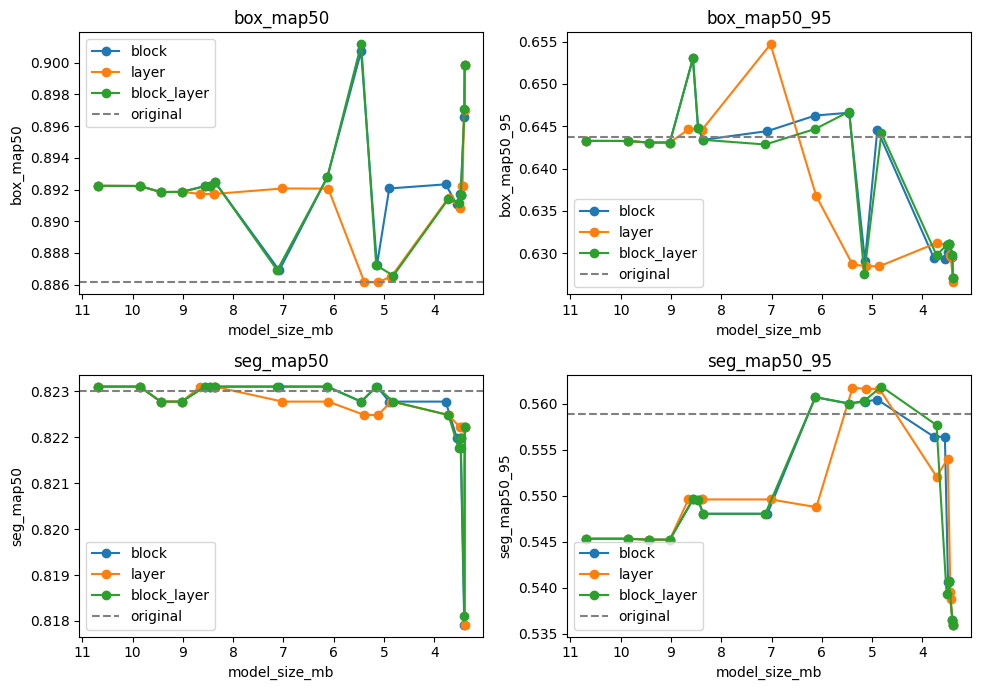

In [ ]:
%matplotlib inline
from plot_json import extractList, plot

arrs=(None, "block", "layer", "block_layer")
extracted = extractList("configs.json", "performance.json", arrs)

plot(extracted, x_label="model_size_mb", metrics=["box_map50", "box_map50_95", "seg_map50", "seg_map50_95"], arrs=arrs)